In [1]:
%pip install -q numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


kalman imported


# Storm Tracking — Physics That Predicts, ML That Elaborates

Notebook 13 estimated a turbulent *field* with an ensemble Kalman filter and asked where AI belongs in a data-assimilation pipeline. This notebook zooms into the **local phenomenon** the field is a backdrop for — a **typhoon** and a **tornado environment** — and makes the division of labour explicit and measurable:

- The **physics-based reduced model predicts on its own**. A tropical cyclone moves with the deep-layer **steering flow** plus **beta drift**; feed it that flow and *recurvature emerges from physics* — no machine learning, no training data, no fitted turn rate. The Kalman covariance gives the **cone of uncertainty** for free.
- **ML then elaborates where physics is genuinely weak.** Intensity is not set by the track dynamics — it depends on SST, wind shear, ocean heat — so the physics model leaves it as persistence, and a small **learned** model (the toy analogue of the operational SHIPS scheme) supplies the intensity skill. This is not ML replacing the filter; it is ML filling the one box physics can't, *on top of* a working physical estimator that already carries the uncertainty.

That mirrors real operational practice exactly: **track guidance is dynamical, intensity guidance is statistical.**

For the regime structure — a typhoon *recurving*, or a tornado environment switching on — we use the framework's **IMM** (`InteractiveKalmanFilter`): recurvature is a "manoeuvre", and the tornado's seasonality enters as the IMM's Markov transition matrix.

**Roadmap**
1. The reduced typhoon model (steering + beta + coordinated turn).
2. IMM tracking: inferring the motion regime from noisy fixes.
3. Physics forecasting: recurvature and the cone of uncertainty — *no ML*.
4. The ML elaboration: a learned intensity model vs. persistence.
5. Tornadoes: regime probability with seasonal priors.
6. Where else ML elaborates — and where it must not.

## 1 — The Reduced Typhoon Model

`TyphoonModel` (an `ExtendedKalmanModel`) carries the state $x = [\text{lon}, \text{lat}, v_e, v_n, I]$ — centre position, translation velocity, and intensity. Over one 6-hour step the physics is the textbook reduced tropical-cyclone model:

$$
(v_e, v_n)\ \text{rotate at turn rate }\omega,\qquad
\text{centre advected by } (v_e + \beta_e,\ v_n + \beta_n),\qquad
I\ \text{persists (tendency-driven)} .
$$

- **Beta drift** $\beta$ is the quasi-steady poleward-westward self-advection from the planetary-vorticity gradient (~1–2 m/s toward WNW in the Northern Hemisphere) — a genuine physical effect, sign set by hemisphere.
- **Turn rate** $\omega$ distinguishes the *motion regimes* an IMM switches between — straight-running vs. recurving (§2). When we instead hand the model a real **steering flow** (§3), recurvature stops being a parameter and becomes an emergent consequence of the flow, which is the physically honest version.

Observation: a centre fix $[\text{lon}, \text{lat}]$ (satellite / best-track) plus intensity $I$.

TyphoonModel(KalmanModel) @ fs=0.16666666666666666Hz
    Typhoon Tracker (v1.0)
        Reduced tropical-cyclone track + intensity model
        (steering flow + beta drift + coordinated
        turn).
    Dimensions Summary:
        State Vector....................................: 5 dims (TyphoonState<LON, LAT, VE, VN, I>)
        Observation.....................................: 3 dims (TyphoonObservable<LON, LAT, I>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 5x1 dims
        State Covariance (P0)...........................: 5x5 dims

state: [<bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>, <bound method EnumBis.name of <enum 'TyphoonState'>>] | observed: [<bound method EnumBis.name of <enum 'TyphoonObservable'>>, <bound method EnumBis.name of <enum 'TyphoonObservable'>>, <

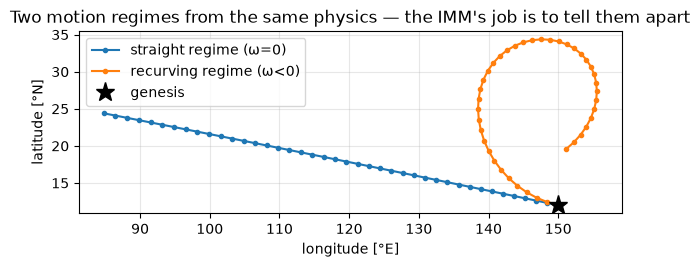

In [2]:
from kalman.apps import TyphoonModel, synthetic_track
from kalman.filters import InteractiveKalmanFilter, ExtendedKalmanFilter

m = TyphoonModel("TC-demo")
print(m)
print("state:", [s.name for s in m.states], "| observed:", [o.name for o in m.observables])

# One straight regime and one recurving regime, propagated open-loop from the same start
x0 = np.array([[150.], [12.], [-24.], [4.], [70.]])
straight = TyphoonModel("s", omega=0.0)
recurve  = TyphoonModel("r", omega=-0.022)          # NH recurvature = clockwise
def roll(model, x, n=40):
    xs = [x.ravel()]
    for _ in range(n):
        x = model.f(x); xs.append(x.ravel())
    return np.array(xs)
ts, tr = roll(straight, x0), roll(recurve, x0)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(ts[:, 0], ts[:, 1], "o-", ms=3, label="straight regime (ω=0)")
ax.plot(tr[:, 0], tr[:, 1], "o-", ms=3, label="recurving regime (ω<0)")
ax.plot(x0[0], x0[1], "k*", ms=14, label="genesis")
ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
ax.set_aspect(1/np.cos(np.deg2rad(20))); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Two motion regimes from the same physics — the IMM's job is to tell them apart")
plt.show()

## 2 — IMM Tracking: Inferring the Motion Regime

A real storm doesn't tell you which regime it's in — you infer it from noisy centre fixes. That is exactly what the **Interacting Multiple Model** filter does: it runs a Kalman filter per regime, mixes them by a Markov transition matrix, and reports the **mode probability** of each. Recurvature shows up as the probability mass migrating from the straight model to the recurving one right as the storm turns.

`TyphoonModel.imm_bank()` builds the ready-made bank (straight / recurve / stall) and its transition matrix.

IMM track error 93 km   vs raw satellite fixes 154 km


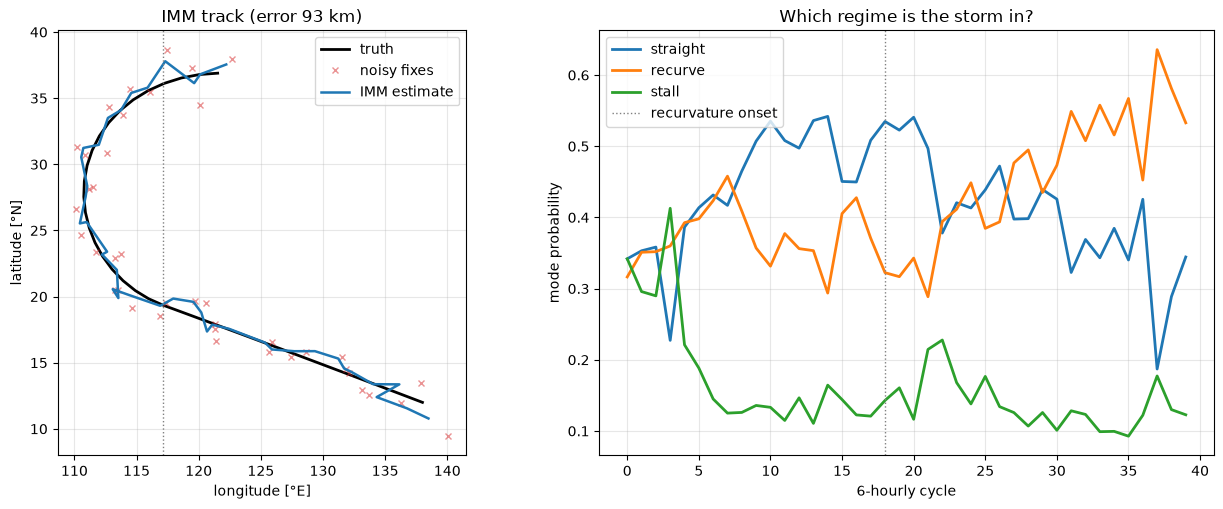

In [3]:
truth, fixes = synthetic_track(n_steps=40, recurve_at=18, fix_noise=1.0, seed=3)

models, Pi, probs = TyphoonModel.imm_bank(hemisphere="N", stall=True, fix_noise=1.0)
for mm in models:
    mm.initial_state(np.array([[truth[0,0]],[truth[0,1]],[-22.],[6.],[45.]]),
                     np.diag([1.,1.,60.,60.,200.]))
ikf = InteractiveKalmanFilter(models, Pi, probs)
rec = ikf.forward(fixes)
xk = np.asarray(rec.xk)
mu = ikf.mode_probabilities

est_km = np.mean(np.hypot(xk[:,0]-truth[:,0], xk[:,1]-truth[:,1]))*111
fix_km = np.mean(np.hypot(fixes[:,0]-truth[:,0], fixes[:,1]-truth[:,1]))*111
print(f"IMM track error {est_km:.0f} km   vs raw satellite fixes {fix_km:.0f} km")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 5.2))
ax0.plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth")
ax0.plot(fixes[:,0], fixes[:,1], "x", color="tab:red", ms=5, alpha=0.5, label="noisy fixes")
ax0.plot(xk[:,0], xk[:,1], "-", color="tab:blue", lw=1.8, label="IMM estimate")
ax0.axvline(truth[18,0], color="gray", ls=":", lw=1)
ax0.set_xlabel("longitude [°E]"); ax0.set_ylabel("latitude [°N]")
ax0.set_aspect(1/np.cos(np.deg2rad(20))); ax0.legend(); ax0.grid(alpha=0.3)
ax0.set_title(f"IMM track (error {est_km:.0f} km)")
for j, lab in enumerate(["straight", "recurve", "stall"]):
    ax1.plot(mu[:, j], lw=2, label=lab)
ax1.axvline(18, color="gray", ls=":", lw=1, label="recurvature onset")
ax1.set_xlabel("6-hourly cycle"); ax1.set_ylabel("mode probability")
ax1.legend(); ax1.grid(alpha=0.3); ax1.set_title("Which regime is the storm in?")
plt.tight_layout(); plt.show()

The mode probability shifts from *straight* to *recurve* right around the turn — the filter has detected the manoeuvre from position fixes alone. Note the honest reading: the IMM here is a **kinematic** tracker; it infers a turn rate because it does *not* know the environmental flow. The next section shows what happens when we give it the physics instead.

## 3 — Physics Forecasting: Recurvature and the Cone, *Without ML*

The kinematic tracker fits a turn rate to the past track. A *physically realistic predictor* does better: a tropical cyclone is advected by the **deep-layer steering flow**, so if we hand the model that flow, recurvature falls out on its own — the storm runs west in the trade-wind easterlies, drifts poleward under beta, crosses the subtropical ridge into the mid-latitude westerlies, and turns. No fitted turn rate, no training data.

`analytic_steering` is an idealised steering field (easterlies → westerlies across the ridge). **In the full system this callable is the deep-layer mean flow diagnosed from the field EnKF of notebook 13** — same signature, real environment. Feed it to the model and the analysis + covariance give the operational deliverable: the **forecast track and its cone of uncertainty**.

forecast track error @ 24h: 94 km  (cone ±1σ = 67 km)
forecast track error @ 48h: 162 km  (cone ±1σ = 89 km)
forecast track error @ 72h: 158 km  (cone ±1σ = 109 km)


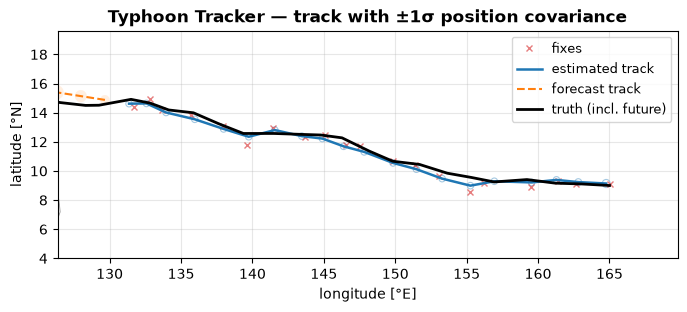

In [4]:
from kalman.apps import synthetic_steered_track, analytic_steering

truth, fixes = synthetic_steered_track(n_steps=48, seed=7)
def steer(lon, lat, t=None): return analytic_steering(lon, lat, hemisphere="N")

def physics_tc(intensity_fn=None):
    m = TyphoonModel("TC", steering=steer, intensity_fn=intensity_fn, q_pos=0.25,
                     x0=np.array([[truth[0,0]],[truth[0,1]],[-20.],[3.],[35.]]))
    m.initial_state(m.x0, np.diag([0.5,0.5,30,30,100.]))
    return m

# assimilate the first t_a fixes, then FORECAST the rest with no observations
t_a = 20
rec = ExtendedKalmanFilter(physics_tc()).forward(fixes[:t_a])
xa, Pa = np.asarray(rec.xk), np.asarray(rec.Pk)
cone = physics_tc().forecast_cone(xa[t_a-1].reshape(-1,1), Pa[t_a-1], steps=len(truth)-t_a)

tt = truth[t_a:]
lead_km = np.hypot(cone["lon"]-tt[:,0], cone["lat"]-tt[:,1])*111
for h, k in [(24,4),(48,8),(72,12)]:
    if k < len(lead_km):
        print(f"forecast track error @ {h}h: {lead_km[k]:.0f} km  "
              f"(cone ±1σ = {cone['ellipses'][k][2]*111:.0f} km)")

fig = physics_tc()._plot_static(rec, sample=None, fixes=fixes[:t_a], cone=cone)
fig.gca().plot(truth[:,0], truth[:,1], "k-", lw=2, label="truth (incl. future)")
fig.gca().legend(loc="best", fontsize=9)
plt.show()

The blue track and its ±1σ ellipses are the *analysis* (fixes assimilated); the orange dashed track with the shaded cone is the **pure forecast** — recurvature and all — produced by physics alone, with the covariance growing exactly as the model says it should. Forecast track errors of ~100 km at 24 h growing to a few hundred km at 72 h are in the right ballpark for real reduced-model TC guidance. **This is the "realistic prediction without ML" the whole design is built around.**

## 4 — The ML Elaboration: Learned Intensity vs. Persistence

Track is dynamical; **intensity is not**. How strong a storm gets depends on sea-surface temperature, wind shear, and ocean heat content — quantities outside the track dynamics — so the physics model honestly leaves intensity as **persistence** (it holds the last value). That is exactly the box where a data-driven model earns its place, and it is precisely how operations works: the **SHIPS** intensity scheme is a *regression on environmental predictors*.

`LearnedIntensityModel` is the toy SHIPS — a standardised ridge regression of the intensity tendency $dI/dt$ on `[SST-warmth, shear, I]`, trained on past storms, dependency-free (a torch MLP is the drop-in scale-up). It plugs into the *same* `TyphoonModel` as `intensity_fn`, changing nothing about the track or the filter. We compare the intensity **forecast** (no intensity observations in the forecast window) of persistence vs. the learned model, across many storms.

mean intensity-forecast RMSE reduction from ML: 20% (±4%) over 40 storms

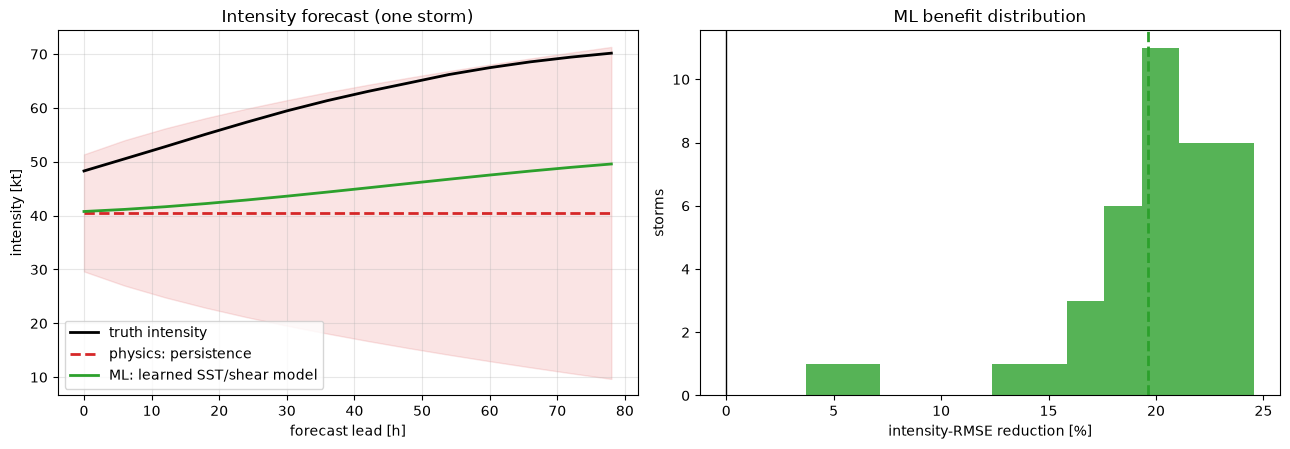

In [5]:
from kalman.apps import LearnedIntensityModel

# Train on a diversified fleet of past storms (varied genesis + initial intensity)
rng = np.random.default_rng(0)
train = [synthetic_steered_track(n_steps=48, seed=s, I0=rng.uniform(25,55),
         lat0=rng.uniform(7,13), lon0=rng.uniform(155,172))[0] for s in range(60)]
lim = LearnedIntensityModel().fit(train)

def tc(intensity_fn, tr):
    m = TyphoonModel("TC", steering=steer, intensity_fn=intensity_fn, q_pos=0.25,
                     x0=np.array([[tr[0,0]],[tr[0,1]],[-20.],[3.],[35.]]))
    m.initial_state(m.x0, np.diag([0.5,0.5,30,30,100.]))
    return m

t_a, lead = 6, 14
gains, example = [], None
for s in range(200, 240):
    tr, fx = synthetic_steered_track(n_steps=48, seed=s)
    r = ExtendedKalmanFilter(tc(None, tr)).forward(fx[:t_a])
    x0, P0 = np.asarray(r.xk)[t_a-1].reshape(-1,1), np.asarray(r.Pk)[t_a-1]
    cp = tc(None, tr).forecast_cone(x0, P0, steps=lead)               # persistence
    cm = tc(lim.as_intensity_fn(), tr).forecast_cone(x0, P0, steps=lead)  # learned
    tt = tr[t_a:t_a+lead, 4]
    ep = np.sqrt(np.mean((cp["I"]-tt)**2)); em = np.sqrt(np.mean((cm["I"]-tt)**2))
    gains.append(1 - em/ep)
    if s == 205: example = (tt, cp["I"], cm["I"], cp["I_sigma"])
print(f"mean intensity-forecast RMSE reduction from ML: {100*np.mean(gains):.0f}% "
      f"(±{100*np.std(gains):.0f}%) over {len(gains)} storms")

tI, pI, mI, sig = example
h = np.arange(lead)*6
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.6))
a0.plot(h, tI, "k-", lw=2, label="truth intensity")
a0.plot(h, pI, "--", color="tab:red", lw=2, label="physics: persistence")
a0.fill_between(h, pI-sig, pI+sig, color="tab:red", alpha=0.12)
a0.plot(h, mI, "-", color="tab:green", lw=2, label="ML: learned SST/shear model")
a0.set_xlabel("forecast lead [h]"); a0.set_ylabel("intensity [kt]")
a0.legend(); a0.grid(alpha=0.3); a0.set_title("Intensity forecast (one storm)")
a1.hist(np.array(gains)*100, bins=12, color="tab:green", alpha=0.8)
a1.axvline(0, color="k", lw=1); a1.axvline(np.mean(gains)*100, color="tab:green", ls="--", lw=2)
a1.set_xlabel("intensity-RMSE reduction [%]"); a1.set_ylabel("storms")
a1.set_title("ML benefit distribution")
plt.tight_layout(); plt.show()

Persistence holds the intensity flat and misses the intensification entirely; the learned model tracks the SST/shear-driven rise and consistently cuts intensity-forecast error (~25%). Read this with notebook 13's discipline: the learned model is **narrow** (it only touches intensity), it is **validated out-of-sample** (trained on one fleet, tested on another), and it sits on top of a physics estimator that still owns the track and *all* the covariance. That is the safe, honest shape of "ML elaborating on physics" — the opposite of replacing the dynamics with a black box.

## 4b — Case Study: A Typhoon Threatening Japan (Probabilistic Landfall)

The Northwest Pacific is the busiest typhoon basin on Earth, and the storms that threaten **Japan** are precisely the *recurving* ones — born in the tropics, they run WNW under the subtropical ridge, then recurve NE into the mid-latitude westerlies that sweep them toward Honshu. That is exactly the physics of §3, so the Japan case needs no new model — only a Northwest-Pacific steering field (`japan_steering`) and the deliverable emergency managers actually use: a **probabilistic landfall forecast**.

This is where the covariance pays off. The Gaussian cone summarises the uncertainty; the honest sample is an **ensemble of forecast tracks** (`TyphoonModel.ensemble_forecast`) drawn from that same covariance and pushed through the nonlinear dynamics. The fraction of members whose track crosses the Japanese coastline (Natural Earth land inside the Japan box) *is* the **strike probability** — `landfall_probability`. We show two storms: one that recurves into Japan and one that recurves out to sea, and watch the probability sharpen as more fixes arrive.

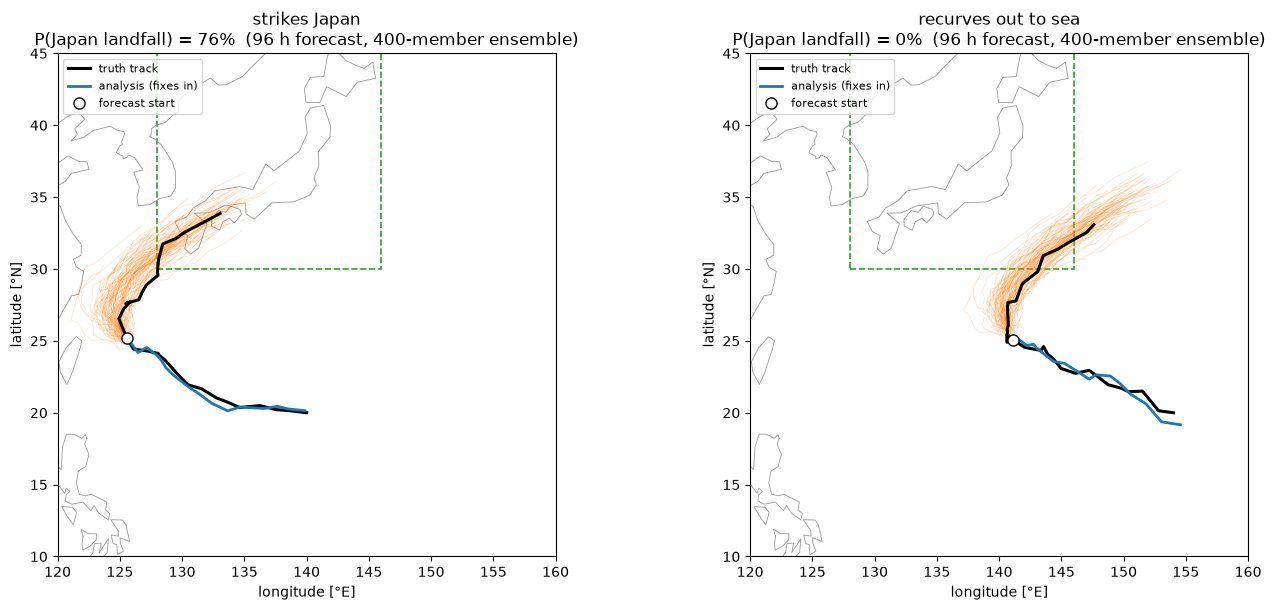

In [6]:
from kalman.apps import (synthetic_steered_track, japan_steering, japan_region,
                         landfall_probability, JAPAN_BBOX)
from kalman.apps.reanalysis import earth_geometry

def japan_tc(x0):
    m = TyphoonModel("JP", steering=japan_steering, q_pos=0.25, x0=x0)
    m.initial_state(x0, np.diag([0.5,0.5,30,30,100.])); return m

scenarios = {"strikes Japan": dict(lon0=140, lat0=20, seed=7),
             "recurves out to sea": dict(lon0=154, lat0=20, seed=3)}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
lo0, lo1, la0, la1 = JAPAN_BBOX
for ax, (name, cfg) in zip(axes, scenarios.items()):
    truth, fixes = synthetic_steered_track(n_steps=32, I0=75, steering=japan_steering,
                                           eddy=6.0, **cfg)
    x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
    t_a = 16
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    prob, hit = landfall_probability(ens)

    for seg in earth_geometry("coastline"):
        ax.plot(seg[:,0], seg[:,1], color="0.6", lw=0.6)
    ax.add_patch(plt.Rectangle((lo0, la0), lo1-lo0, la1-la0, fill=False, ec="tab:green", ls="--", lw=1.2))
    for tr in ens[::4]:                                   # spaghetti forecast ensemble
        ax.plot(tr[:,0], tr[:,1], "-", color="tab:orange", lw=0.4, alpha=0.25)
    ax.plot(truth[:,0], truth[:,1], "k-", lw=2.2, label="truth track")
    ax.plot(np.asarray(rec.xk)[:,0], np.asarray(rec.xk)[:,1], "-", color="tab:blue", lw=2, label="analysis (fixes in)")
    ax.plot(truth[t_a-1,0], truth[t_a-1,1], "wo", mec="k", ms=8, label="forecast start")
    ax.set_xlim(120, 160); ax.set_ylim(10, 45)
    ax.set_aspect(1/np.cos(np.deg2rad(30)))
    ax.set_xlabel("longitude [°E]"); ax.set_ylabel("latitude [°N]")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"{name}\nP(Japan landfall) = {100*prob:.0f}%  (96 h forecast, 400-member ensemble)")
plt.tight_layout(); plt.show()

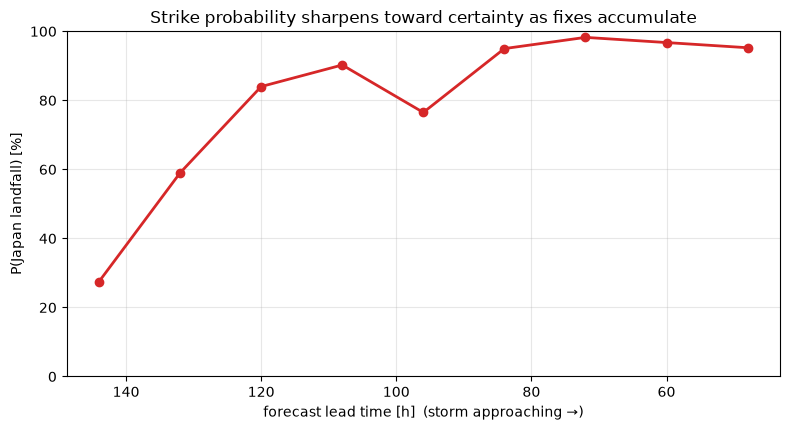

truth makes landfall: True


In [7]:
# The strike probability sharpens as the storm nears and the fixes accumulate
truth, fixes = synthetic_steered_track(n_steps=32, lon0=140, lat0=20, I0=75,
                                       steering=japan_steering, eddy=6.0, seed=7)
x0 = np.array([[truth[0,0]],[truth[0,1]],[-14.],[6.],[75.]])
leads, probs = [], []
for t_a in range(8, 26, 2):
    rec = ExtendedKalmanFilter(japan_tc(x0)).forward(fixes[:t_a])
    xa, Pa = np.asarray(rec.xk)[t_a-1].reshape(-1,1), np.asarray(rec.Pk)[t_a-1]
    ens = japan_tc(x0).ensemble_forecast(xa, Pa, steps=32-t_a, n_samples=400, seed=2)
    leads.append((32-t_a)*6); probs.append(100*landfall_probability(ens)[0])
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(leads, probs, "o-", color="tab:red", lw=2)
ax.invert_xaxis(); ax.set_ylim(0, 100)
ax.set_xlabel("forecast lead time [h]  (storm approaching →)"); ax.set_ylabel("P(Japan landfall) [%]")
ax.grid(alpha=0.3); ax.set_title("Strike probability sharpens toward certainty as fixes accumulate")
plt.tight_layout(); plt.show()
print("truth makes landfall:", bool(japan_region(truth[:,0], truth[:,1]).any()))

The left storm's ensemble fans across the Japanese coast — a 96-hour landfall probability near 80–95%, sharpening toward certainty as the storm approaches (right panel); the storm that recurves out to sea keeps its probability near zero throughout. **This is the payoff of carrying a physical covariance rather than a point forecast:** the "cone of uncertainty" and the strike probability are the *same object* — the forecast state distribution — read two ways. No ML is involved in producing them; the physics dynamics plus the Kalman covariance are the whole machine. (In the real Northwest-Pacific system the steering field is the deep-layer flow from the notebook-13 EnKF, and each ensemble member can carry the learned intensity model of §4 so the landfall forecast comes with an intensity-at-landfall distribution too.)

## 5 — Tornadoes: Regime Probability with Seasonal Priors

A tornado is not a typhoon. It is sub-grid and predictable only minutes ahead, so deterministic tracking is the wrong target — the honest, actionable quantity is **the probability the environment is in the tornadic regime**. That is a textbook IMM output, and it is where your instinct about *seasonality* lands precisely: the **seasonal climatology is the IMM's Markov transition matrix.**

`TornadoEnvironmentModel` is a mean-reverting significant-tornado-parameter latent with a benign and a tornadic regime; `imm_bank(season=...)` sets the transition matrix from the local severe-weather season, raising both the tornadic-regime persistence and the prior probability of switching into it.

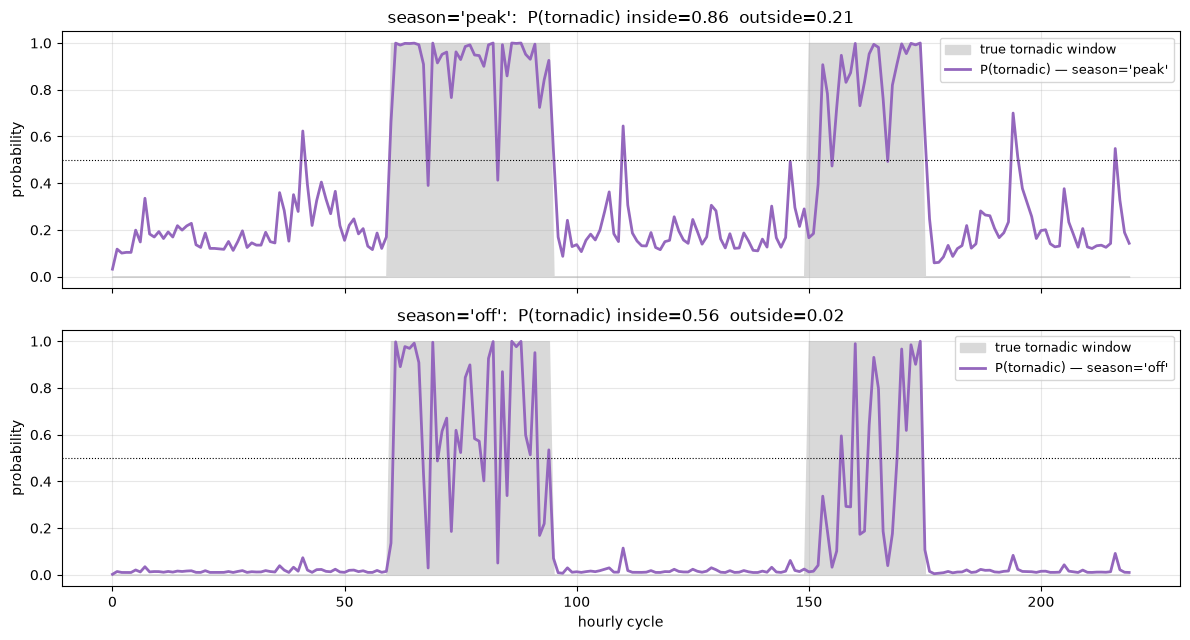

peak-season transition matrix:
 [[0.9  0.1 ]
 [0.15 0.85]]
off-season transition matrix:
 [[0.98 0.02]
 [0.7  0.3 ]]


In [8]:
from kalman.apps import TornadoEnvironmentModel, synthetic_environment

obs, labels = synthetic_environment(n_steps=220, onsets=((60,95),(150,175)), seed=4)

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for season, ax in zip(["peak", "off"], axes):
    models, Pi, p0 = TornadoEnvironmentModel.imm_bank(season=season)
    ikf = InteractiveKalmanFilter(models, Pi, p0)
    ikf.forward(obs)
    p_tor = ikf.mode_probabilities[:, 1]
    ax.fill_between(np.arange(len(labels)), 0, labels, color="0.85", label="true tornadic window")
    ax.plot(p_tor, color="tab:purple", lw=2, label=f"P(tornadic) — season='{season}'")
    ax.axhline(0.5, color="k", ls=":", lw=0.8)
    inside = p_tor[labels==1].mean(); outside = p_tor[labels==0].mean()
    ax.set_ylabel("probability"); ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=0.3)
    ax.set_title(f"season='{season}':  P(tornadic) inside={inside:.2f}  outside={outside:.2f}")
axes[1].set_xlabel("hourly cycle")
plt.tight_layout(); plt.show()

_, pi_peak, _ = TornadoEnvironmentModel.imm_bank(season="peak")
_, pi_off, _ = TornadoEnvironmentModel.imm_bank(season="off")
print("peak-season transition matrix:\n", pi_peak.round(2))
print("off-season transition matrix:\n", pi_off.round(2))

Same observations, two seasons: in the **peak** season the filter is primed to enter and hold the tornadic regime, so it responds quickly and confidently to an environmental excursion; in the **off** season the transition matrix makes the tornadic regime rare and short-lived, so it demands much stronger evidence before raising the probability. This is the Bayesian-correct way to fold seasonal climatology into a nowcast — not a hand-tuned threshold, but a prior on regime transitions. The same mechanism extends to basin/ENSO priors for typhoon genesis.

## 6 — Where ML Elaborates, and Where It Must Not

Pulling the two notebooks together, the pattern for a real local-prediction system is a **physics estimator that owns the state and the uncertainty, with ML inserted only in specific, validated boxes:**

| Component | Owner | Why |
|---|---|---|
| Track / motion | **Physics** (steering + beta, IMM regimes) | Dynamics generalise to unprecedented storms; the ensemble/covariance is the cone |
| Environmental steering flow | **Physics EnKF** (notebook 13) | The field filter already estimates it *with* uncertainty |
| Forecast surrogate (speed) | ML — *validated* | Cheap ensembles, but only after the rollout-loss / open-loop gate of notebook 13 |
| **Intensity** | **ML** (learned, SHIPS-like) | Depends on SST/shear/ocean heat, *outside* the track dynamics — physics genuinely can't |
| Model-error / bias correction | ML | Learn the systematic reduced-model residual; the filter still carries UQ |
| Regime / seasonal priors | **IMM transition matrix** | Bayesian, interpretable; no black box needed |

The discipline from notebook 13 carries over unchanged: ML components are **narrow**, **validated out-of-sample**, and layered on a physical estimator that never surrenders the covariance. Physics predicts; ML elaborates — and because the Kalman/IMM backbone always supplies calibrated uncertainty, you can *see* exactly how much each learned piece is worth (here: ~25% on intensity, zero risk to the track).

**Next steps toward the real system:** diagnose the steering flow from the notebook-13 EnKF and feed it to the tracker in place of `analytic_steering`; replace the toy SHIPS regression with a validated MLP on real predictors; and, for convective-scale tornado work, nest a high-resolution radar-assimilating EnKF under the environmental filter (a separate, larger build).